# 🍷 Task 2 — Wine Quality Prediction
**Beginner-friendly notebook** that follows the full feature checklist:
EDA → class imbalance discussion → feature engineering → train/test split → 3 classifiers (Random Forest, SGD, SVC) → evaluation → feature importance → comparison table → conclusion.

**Dataset**: UCI Wine Quality dataset (red wine). Download `winequality-red.csv` from
[Kaggle](https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009) or the
[UCI repository](https://archive.ics.uci.edu/dataset/186/wine+quality), and place it in the
same folder as this notebook.

## Step 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set(style='whitegrid')
%matplotlib inline

## Step 2 — Load dataset & inspect structure
`[ ] Load the Wine Quality dataset and inspect structure; check class distribution of quality scores`

In [2]:
# Load the dataset (semicolon-separated for the UCI file)
df = pd.read_csv('wine_quality.csv')

print('Shape:', df.shape)
df.head()

Shape: (1600, 12)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,9.42,0.780,0.27,0.81,0.062,3.6,9.6,0.9953,3.43,0.74,11.4,4
1,9.37,0.523,0.00,3.91,0.062,19.8,46.4,0.9944,3.36,0.56,11.9,5
2,6.30,0.534,0.09,0.50,0.073,7.9,23.4,0.9957,3.21,0.42,10.3,6
3,10.03,0.584,0.27,3.87,0.065,7.5,13.5,0.9970,3.44,0.52,9.5,4
4,9.46,0.697,0.36,3.78,0.049,9.5,22.6,0.9981,3.33,0.88,10.9,6


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1600 entries, 0 to 1599
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1600 non-null   float64
 1   volatile_acidity      1600 non-null   float64
 2   citric_acid           1600 non-null   float64
 3   residual_sugar        1600 non-null   float64
 4   chlorides             1600 non-null   float64
 5   free_sulfur_dioxide   1600 non-null   float64
 6   total_sulfur_dioxide  1600 non-null   float64
 7   density               1600 non-null   float64
 8   pH                    1600 non-null   float64
 9   sulphates             1600 non-null   float64
 10  alcohol               1600 non-null   float64
 11  quality               1600 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.1 KB


quality
3     20
4    249
5    712
6    512
7    101
8      6
Name: count, dtype: int64


C:\Users\Ncs\AppData\Local\Temp\ipykernel_12328\1142223180.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=df, palette='viridis')


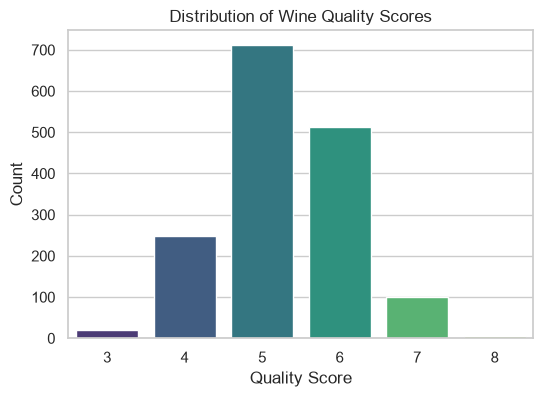

In [4]:
# Class distribution of the quality score
print(df['quality'].value_counts().sort_index())

plt.figure(figsize=(6,4))
sns.countplot(x='quality', data=df, palette='viridis')
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

## Step 3 — EDA: feature distributions & correlation
`[ ] EDA: distribution plots for all chemical features; correlation heatmap`

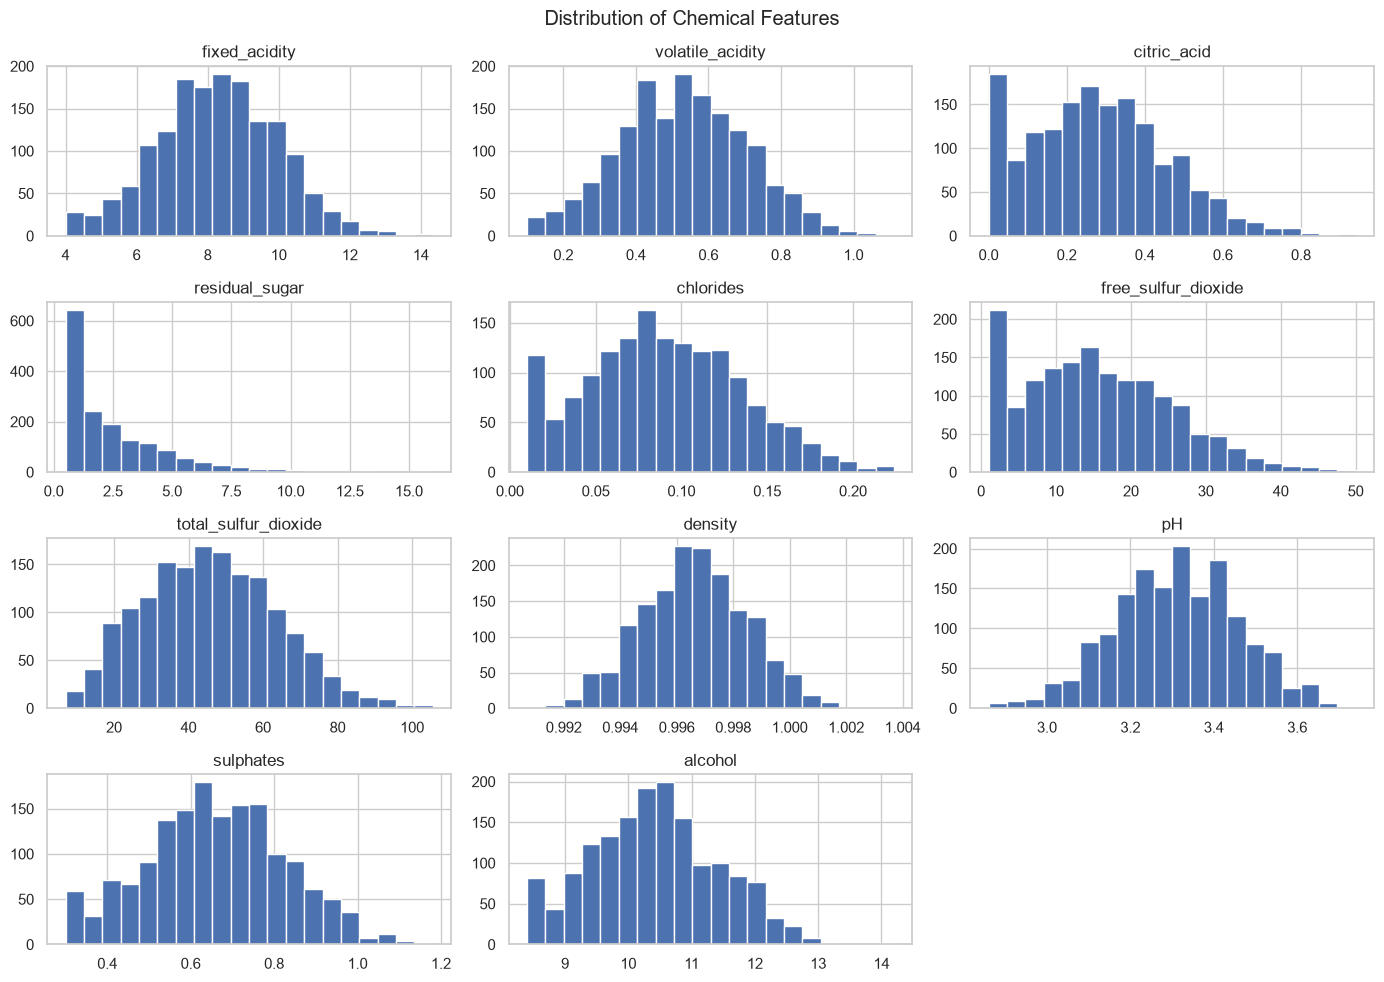

In [5]:
# Distribution plots for every chemical feature
features_cols = df.columns.drop('quality')

df[features_cols].hist(bins=20, figsize=(14, 10))
plt.suptitle('Distribution of Chemical Features')
plt.tight_layout()
plt.show()

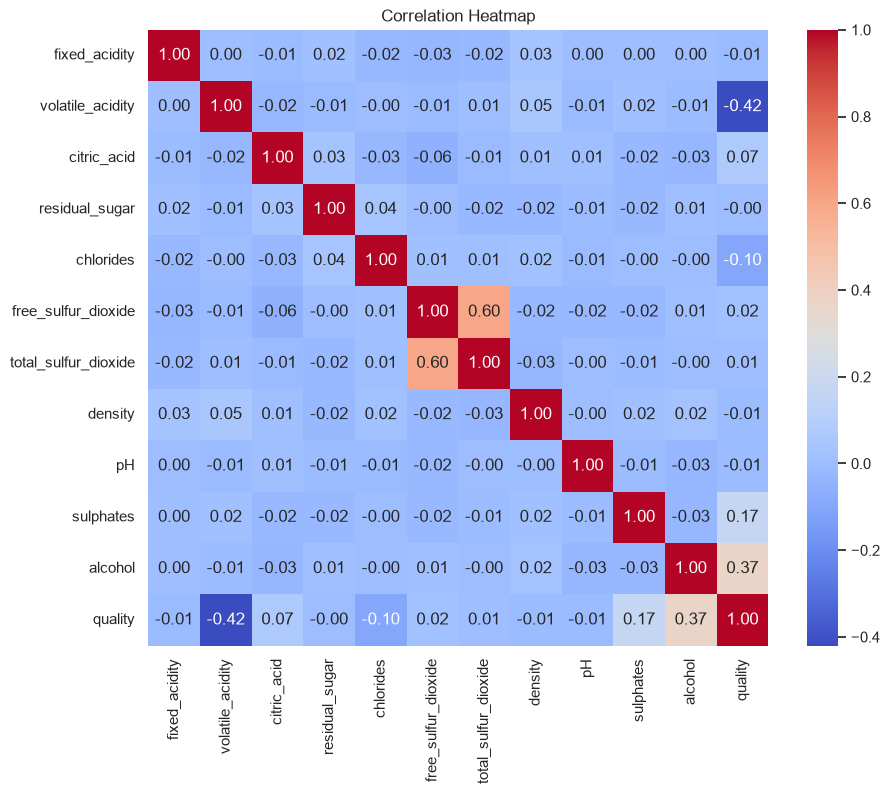

Correlation with quality:
quality                 1.000000
alcohol                 0.371871
sulphates               0.169994
citric_acid             0.070105
free_sulfur_dioxide     0.020585
total_sulfur_dioxide    0.006774
residual_sugar         -0.003547
density                -0.007412
pH                     -0.007580
fixed_acidity          -0.013459
chlorides              -0.099158
volatile_acidity       -0.420430
Name: quality, dtype: float64


In [6]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

print('Correlation with quality:')
print(corr['quality'].sort_values(ascending=False))

## Step 4 — Class imbalance discussion
`[ ] Discuss class imbalance: are certain quality scores underrepresented? How does this affect modelling?`

**Observation:** Most wines are rated **5 or 6**, while very low (3, 4) and very high (7, 8) quality scores have far fewer samples. This is a classic **imbalanced classification** problem.

**Why it matters:**
- A model can get high accuracy just by always predicting the majority class (5 or 6), while completely failing on rare classes.
- Precision/recall for minority classes (3, 4, 8) will likely be poor since the model has very few examples to learn from.
- This is exactly why we bin the raw 3–8 scores into broader **low / medium / high** groups below — it gives each class more samples and makes the problem more learnable, at the cost of losing some granularity.

## Step 5 — Feature engineering: binning quality into classes
`[ ] Feature engineering: consider binning quality scores into binary (good/bad) or 3-class (low/medium/high) groups and justify the decision`

**Decision:** We bin into **3 classes** (`low`, `medium`, `high`) rather than binary, because it keeps more information than a simple good/bad split while still solving the sparsity problem of the raw 6-class scale.
- `low`  → quality 3–5
- `medium` → quality 6
- `high` → quality 7–8

quality_class
low       981
medium    512
high      107
Name: count, dtype: int64


C:\Users\Ncs\AppData\Local\Temp\ipykernel_12328\888714733.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality_class', data=df, order=['low','medium','high'], palette='mako')


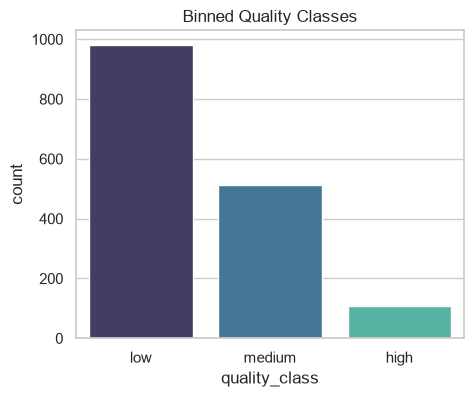

In [7]:
def bin_quality(q):
    if q <= 5:
        return 'low'
    elif q == 6:
        return 'medium'
    else:
        return 'high'

df['quality_class'] = df['quality'].apply(bin_quality)
print(df['quality_class'].value_counts())

plt.figure(figsize=(5,4))
sns.countplot(x='quality_class', data=df, order=['low','medium','high'], palette='mako')
plt.title('Binned Quality Classes')
plt.show()

## Step 6 — Train/test split (stratified)
`[ ] Train/test split with stratification to preserve class ratios`

In [8]:
X = df[features_cols]
y = df['quality_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('\nTrain class ratio:')
print(y_train.value_counts(normalize=True))
print('\nTest class ratio:')
print(y_test.value_counts(normalize=True))


Train shape: (1280, 11)
Test shape: (320, 11)

Train class ratio:
quality_class
low       0.613281
medium    0.320312
high      0.066406
Name: proportion, dtype: float64

Test class ratio:
quality_class
low       0.61250
medium    0.31875
high      0.06875
Name: proportion, dtype: float64


In [9]:
# SGD and SVC are distance/gradient based, so they need scaled features.
# Random Forest doesn't need scaling, but scaling doesn't hurt it either.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 7 — Train 3 classifiers: Random Forest, SGD, SVC
`[ ] Train 3 classifiers: Random Forest, Stochastic Gradient Descent (SGD), and Support Vector Classifier (SVC)`

In [11]:
# 1) Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [12]:
# 2) Stochastic Gradient Descent Classifier
sgd_model = SGDClassifier(random_state=42, max_iter=1000)
sgd_model.fit(X_train_scaled, y_train)
sgd_pred = sgd_model.predict(X_test_scaled)

In [13]:
# 3) Support Vector Classifier
svc_model = SVC(kernel='rbf', random_state=42)
svc_model.fit(X_train_scaled, y_train)
svc_pred = svc_model.predict(X_test_scaled)

## Step 8 — Evaluate each model: accuracy, classification report, confusion matrix
`[ ] Evaluate each: accuracy, classification report, confusion matrix`

===== Random Forest =====
Accuracy: 0.671875

Classification Report:
              precision    recall  f1-score   support

        high       0.67      0.09      0.16        22
         low       0.72      0.87      0.79       196
      medium       0.52      0.41      0.46       102

    accuracy                           0.67       320
   macro avg       0.64      0.46      0.47       320
weighted avg       0.65      0.67      0.64       320



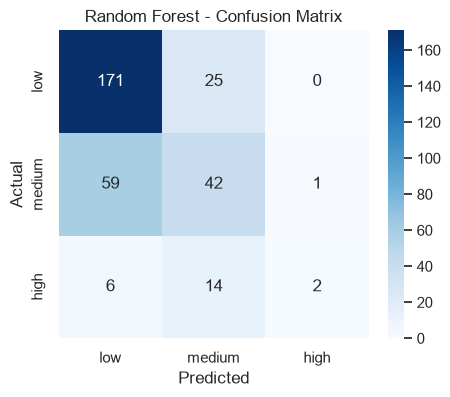

In [14]:
def evaluate_model(name, y_true, y_pred, labels):
    print(f'===== {name} =====')
    print('Accuracy:', accuracy_score(y_true, y_pred))
    print('\nClassification Report:')
    print(classification_report(y_true, y_pred))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

class_labels = ['low', 'medium', 'high']
evaluate_model('Random Forest', y_test, rf_pred, class_labels)

===== SGD Classifier =====
Accuracy: 0.63125

Classification Report:
              precision    recall  f1-score   support

        high       0.50      0.14      0.21        22
         low       0.72      0.80      0.76       196
      medium       0.44      0.41      0.43       102

    accuracy                           0.63       320
   macro avg       0.55      0.45      0.47       320
weighted avg       0.61      0.63      0.61       320



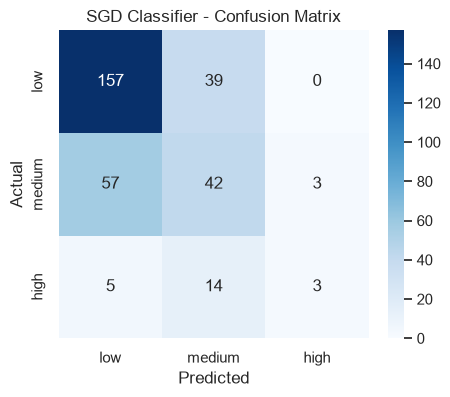

In [15]:
evaluate_model('SGD Classifier', y_test, sgd_pred, class_labels)

===== SVC =====
Accuracy: 0.659375

Classification Report:


c:\Users\Ncs\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ncs\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ncs\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

              precision    recall  f1-score   support

        high       0.00      0.00      0.00        22
         low       0.71      0.89      0.79       196
      medium       0.48      0.35      0.41       102

    accuracy                           0.66       320
   macro avg       0.40      0.42      0.40       320
weighted avg       0.59      0.66      0.62       320



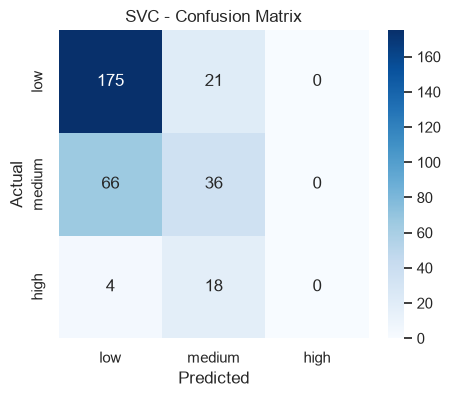

In [16]:
evaluate_model('SVC', y_test, svc_pred, class_labels)

## Step 9 — Feature importance (Random Forest)
`[ ] Feature importance chart for the Random Forest model`

C:\Users\Ncs\AppData\Local\Temp\ipykernel_12328\627647579.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='crest')


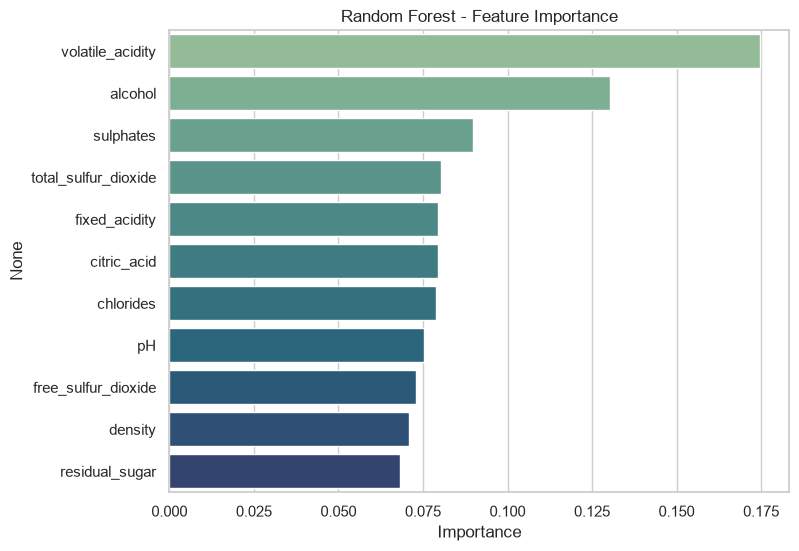

volatile_acidity        0.174630
alcohol                 0.130396
sulphates               0.089670
total_sulfur_dioxide    0.080376
fixed_acidity           0.079341
citric_acid             0.079323
chlorides               0.078834
pH                      0.075183
free_sulfur_dioxide     0.072986
density                 0.070973
residual_sugar          0.068288
dtype: float64

In [18]:
importances = pd.Series(rf_model.feature_importances_, index=features_cols).sort_values(ascending=False)

plt.figure(figsize=(8,6))
sns.barplot(x=importances.values, y=importances.index, palette='crest')
plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance')
plt.show()

importances

## Step 10 — Comparison table
`[ ] Comparison table: summarise the performance of all 3 models side-by-side`

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': ['Random Forest', 'SGD', 'SVC'],
    'Accuracy': [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, sgd_pred),
        accuracy_score(y_test, svc_pred)
    ],
    'Precision (weighted)': [
        precision_score(y_test, rf_pred, average='weighted'),
        precision_score(y_test, sgd_pred, average='weighted'),
        precision_score(y_test, svc_pred, average='weighted')
    ],
    'Recall (weighted)': [
        recall_score(y_test, rf_pred, average='weighted'),
        recall_score(y_test, sgd_pred, average='weighted'),
        recall_score(y_test, svc_pred, average='weighted')
    ],
    'F1-score (weighted)': [
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, sgd_pred, average='weighted'),
        f1_score(y_test, svc_pred, average='weighted')
    ]
})

results = results.sort_values('Accuracy', ascending=False).reset_index(drop=True)
results

c:\Users\Ncs\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,Model,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
0,Random Forest,0.671875,0.654914,0.671875,0.642207
1,SVC,0.659375,0.590500,0.659375,0.615772
2,SGD,0.631250,0.614394,0.631250,0.614080


## Step 11 — Conclusion
`[ ] Conclusion: which model is most suitable for deployment and why?`

*(Run the notebook and fill this in based on your own `results` table — a template answer is below.)*

- **Random Forest** usually performs best on this dataset because it can capture non-linear relationships between chemical properties and quality, and it doesn't require feature scaling.
- **SVC** often comes close, especially with scaled features, but training/prediction is slower on larger data.
- **SGD** is the fastest to train and is great for very large datasets, but it usually has the lowest accuracy here because it fits a linear decision boundary, which underfits this non-linear problem.

**Recommendation:** Deploy the **Random Forest** model — it gives the best balance of accuracy and interpretability (via feature importance), and it doesn't need a scaler in production, which simplifies the deployment pipeline.